# Issue #6 — Análise dos 360 experimentos e EDA
**Eric · Ciência de Dados — Equipe 5**

Este notebook lê `results/experimentos_knn.csv` e o CSV original da APAC. Os experimentos **não são reexecutados**, apenas interpretados. Atenção: o CSV de experimentos enviado foi produzido antes das seis correções de mesorregiões da Issue #4; portanto, suas métricas são **históricas**, enquanto os gráficos EDA usam o mapeamento atualmente disponível em `src/meso_map.py`. Para reportar métricas do modelo corrigido, reexecutar `python src/experimentos.py`.

**Método:** 5 folds agrupados por código do posto (`StratifiedGroupKFold`, seed 42); `f1_std` no CSV representa desvio entre folds para cada configuração. O desvio mostrado nos gráficos agregados por fator descreve a variação **entre configurações**, e não o desvio entre folds.

In [1]:
from pathlib import Path
import sys
import pandas as pd
from IPython.display import display, Markdown, Image
ROOT = Path.cwd() if (Path.cwd() / 'src' / 'data.py').exists() else Path.cwd().parent
sys.path.insert(0, str(ROOT / 'src'))
from data import carregar, MESES
from eda_graficos import graficos, FIG
ARQUIVOS = sorted((ROOT / 'data' / 'raw').glob('*.csv'))
assert len(ARQUIVOS) == 1, 'Esperado exatamente um CSV em data/raw/'
df = carregar(str(ARQUIVOS[0]))
exp = pd.read_csv(ROOT / 'results' / 'experimentos_knn.csv')
assert len(exp) == 360, f'Esperados 360 experimentos, recebidos {len(exp)}'
print('Base original:', df.shape, '| Experimentos:', exp.shape, '| Arquivo de origem:', ARQUIVOS[0].name)
print('Classes:', df['Mesorregiao'].nunique(), '| Falhas de mapeamento:', df['Mesorregiao'].isna().sum())

Base original: (5104, 18) | Experimentos: (360, 14) | Arquivo de origem: Dataset APAC - P#U00e1gina1.csv
Classes: 5 | Falhas de mapeamento: 0


## 1. Top 10 configurações por F1 macro

In [2]:
colunas = ['id','max_ausentes','n_instancias','imputador','scaler','metrica','pesos','k','f1_macro','f1_std','acc']
top10 = exp.sort_values('f1_macro',ascending=False).head(10)
display(top10[colunas].round(4))
print('Maior F1 macro:',round(top10.iloc[0]['f1_macro'],6))

,id,max_ausentes,n_instancias,imputador,scaler,metrica,pesos,k,f1_macro,f1_std,acc
0,197,6.0,3337,mediana,standard,manhattan,distance,5,0.7224,0.0436,0.7537
1,227,6.0,3337,mediana,minmax,manhattan,distance,5,0.7212,0.0401,0.7525
2,233,6.0,3337,mediana,minmax,manhattan,distance,7,0.7191,0.0428,0.7570
3,317,6.0,3337,knn_imputer,minmax,manhattan,distance,5,0.7191,0.0569,0.7468
4,353,6.0,3337,knn_imputer,robust,manhattan,distance,7,0.7186,0.0490,0.7483
5,323,6.0,3337,knn_imputer,minmax,manhattan,distance,7,0.7183,0.0607,0.7489
6,299,6.0,3337,knn_imputer,standard,manhattan,distance,9,0.7179,0.0508,0.7507
7,347,6.0,3337,knn_imputer,robust,manhattan,distance,5,0.7173,0.0610,0.7453
8,287,6.0,3337,knn_imputer,standard,manhattan,distance,5,0.7171,0.0566,0.7450
9,359,6.0,3337,knn_imputer,robust,manhattan,distance,9,0.7163,0.0490,0.7489


Maior F1 macro: 0.722351


## 2. Fatores dos 360 experimentos
Os gráficos mostram **média do F1 macro entre todas as configurações daquele nível**, desvio-padrão entre configurações e o **máximo observado**. São análises marginais exploratórias: os fatores interagem; não atribuir causalidade individual ao maior valor agregado.

**Limite de ausentes: média, máximo, desvio entre configurações e quantidade de experimentos**

,mean,max,std,count
max_ausentes,,,,
6.0,0.6657,0.7224,0.0385,180
Sem limite,0.4972,0.5811,0.0670,180


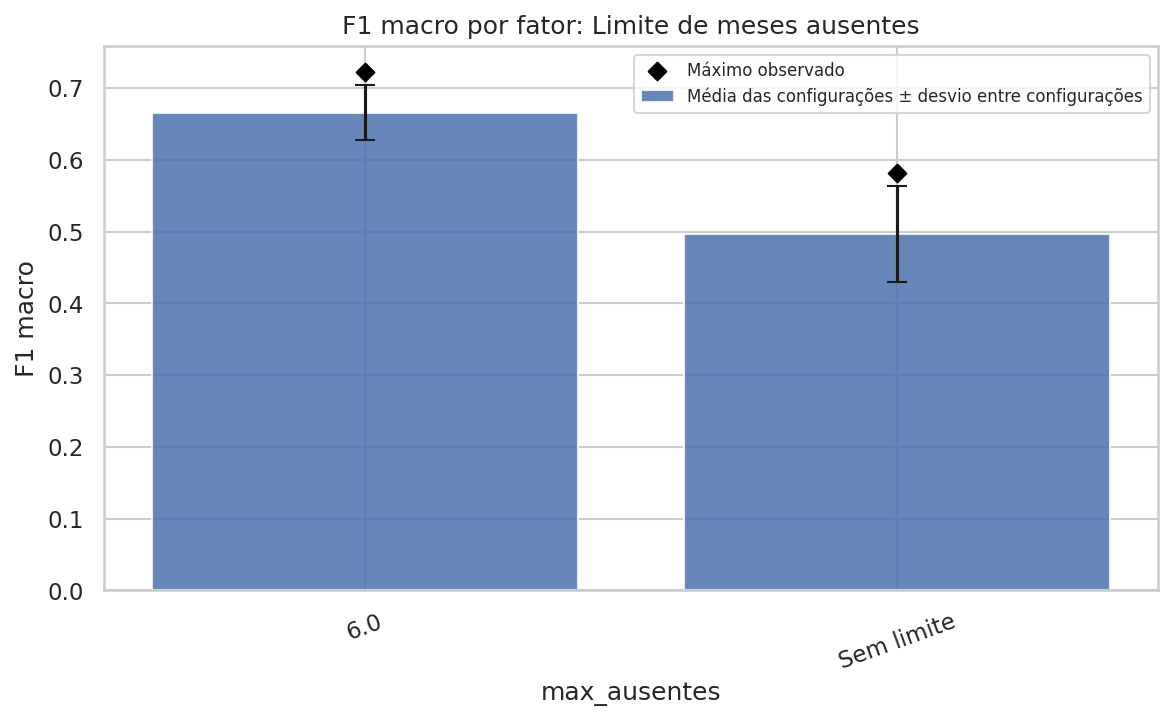

Leitura: Limite de ausentes — o maior F1 observado é 0.7224 ; a média do nível líder é 0.6657 .


**Imputação: média, máximo, desvio entre configurações e quantidade de experimentos**

,mean,max,std,count
imputador,,,,
knn_imputer,0.5995,0.7191,0.0809,180
mediana,0.5634,0.7224,0.1142,180


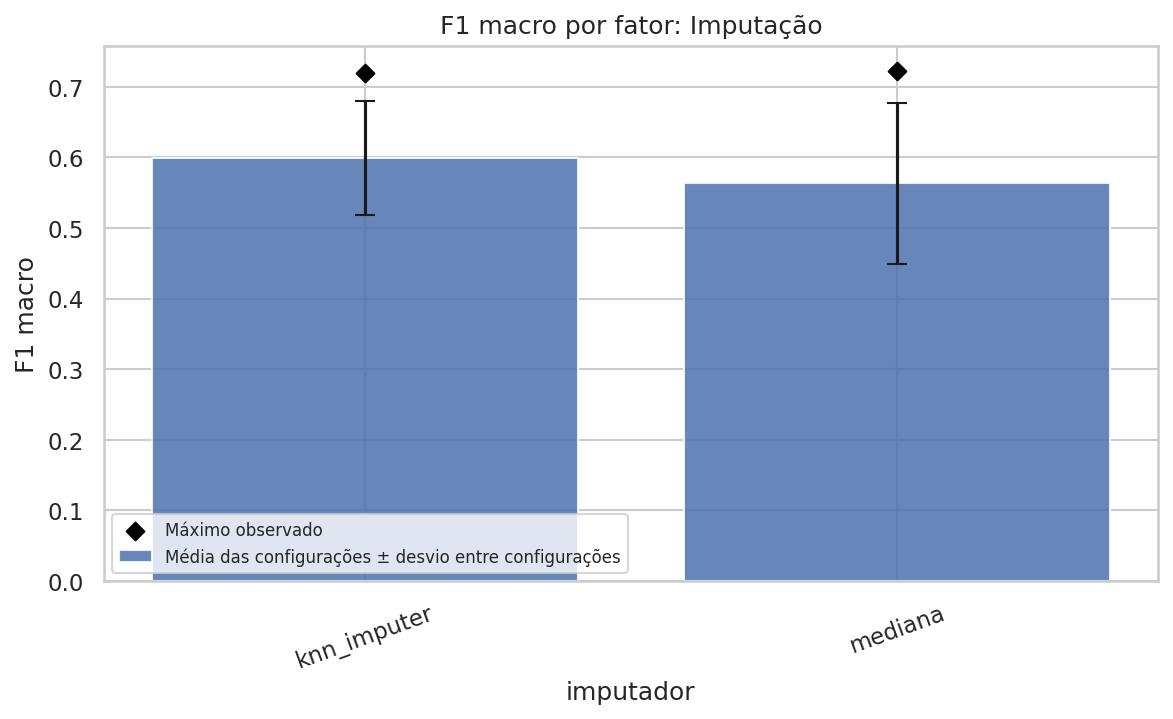

Leitura: Imputação — o maior F1 observado é 0.7224 ; a média do nível líder é 0.5995 .


**Scaler: média, máximo, desvio entre configurações e quantidade de experimentos**

,mean,max,std,count
scaler,,,,
minmax,0.5962,0.7212,0.0795,120
standard,0.5961,0.7224,0.0796,120
robust,0.5520,0.7186,0.1284,120


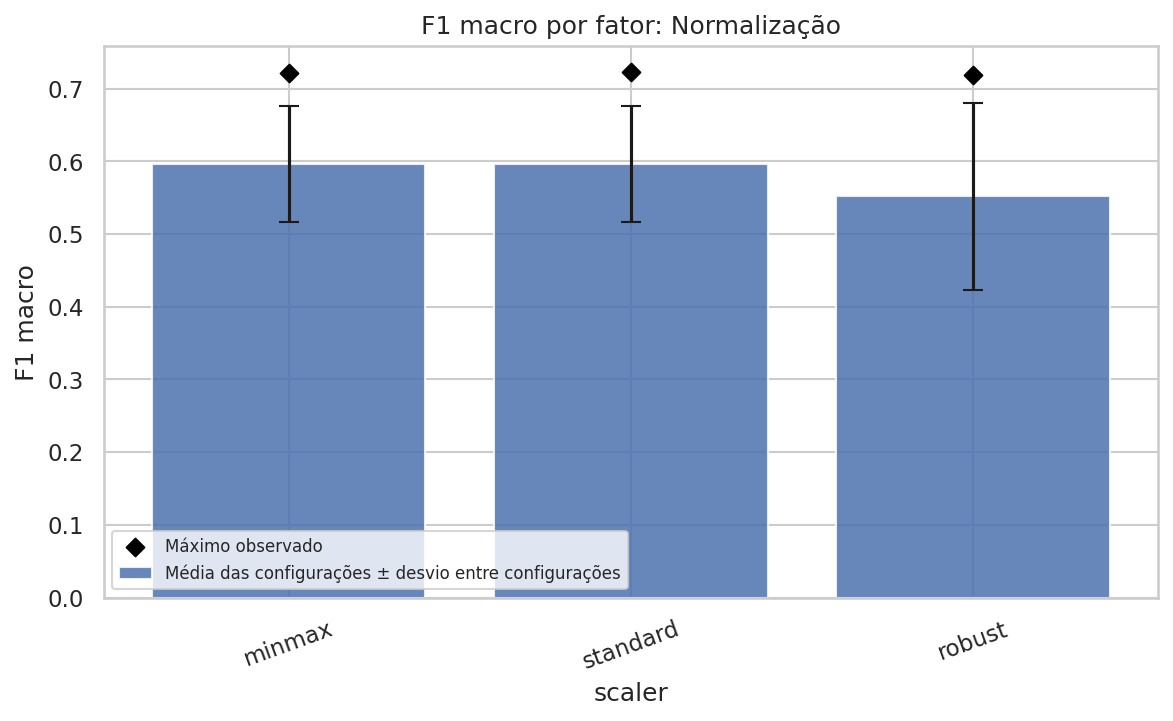

Leitura: Scaler — o maior F1 observado é 0.7224 ; a média do nível líder é 0.5962 .


**Distância: média, máximo, desvio entre configurações e quantidade de experimentos**

,mean,max,std,count
metrica,,,,
manhattan,0.6152,0.7224,0.0966,120
euclidean,0.5882,0.7046,0.0991,120
chebyshev,0.5409,0.6579,0.0920,120


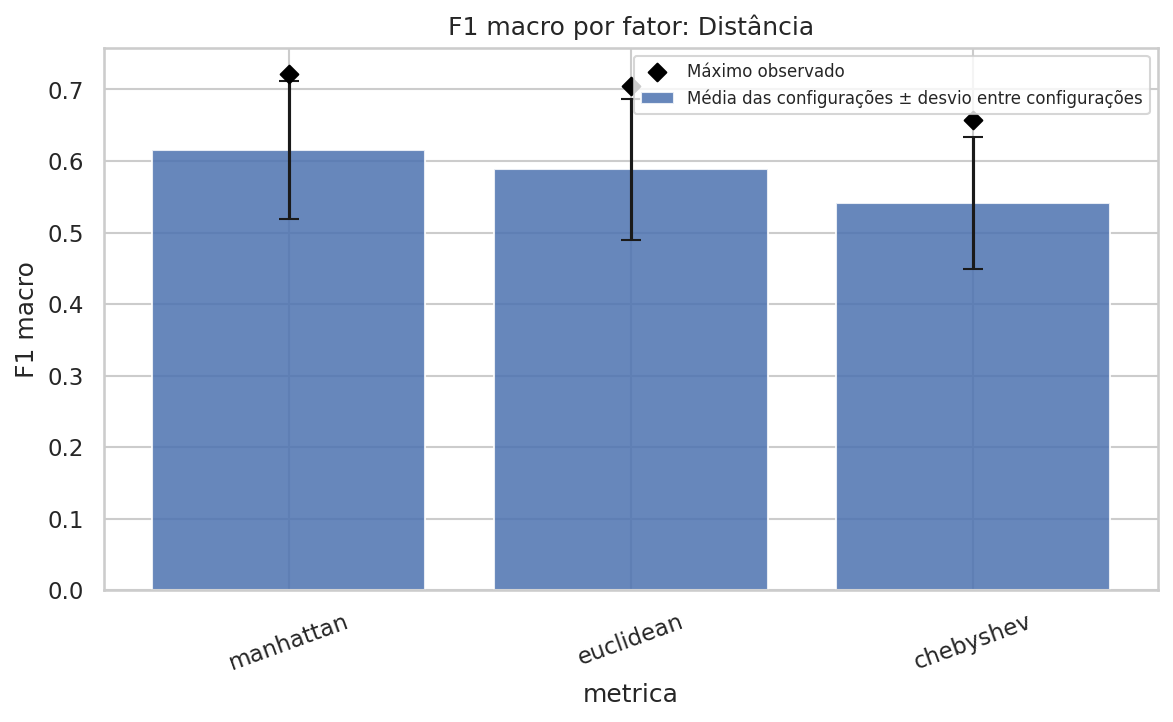

Leitura: Distância — o maior F1 observado é 0.7224 ; a média do nível líder é 0.6152 .


**Pesos: média, máximo, desvio entre configurações e quantidade de experimentos**

,mean,max,std,count
pesos,,,,
distance,0.5897,0.7224,0.0999,180
uniform,0.5732,0.7075,0.1006,180


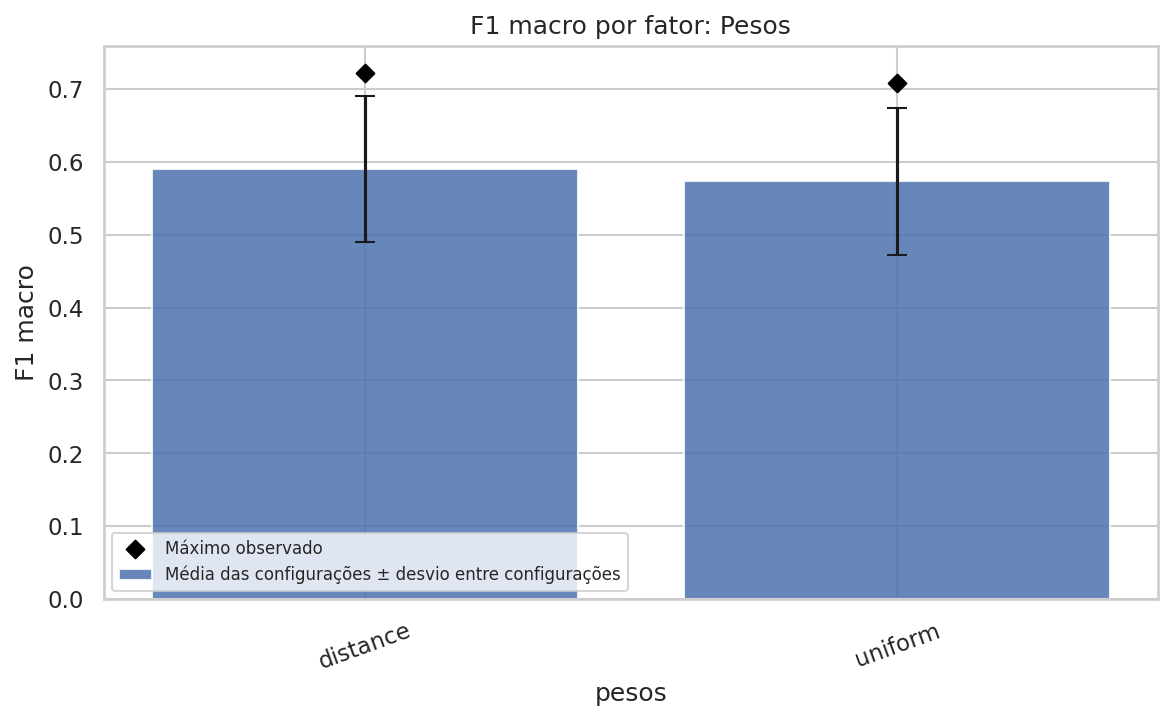

Leitura: Pesos — o maior F1 observado é 0.7224 ; a média do nível líder é 0.5897 .


**Vizinhos k: média, máximo, desvio entre configurações e quantidade de experimentos**

,mean,max,std,count
k,,,,
3,0.5859,0.7155,0.0992,72
5,0.5844,0.7224,0.1028,72
1,0.5842,0.7001,0.0945,72
7,0.5787,0.7191,0.1039,72
9,0.5741,0.7179,0.1040,72


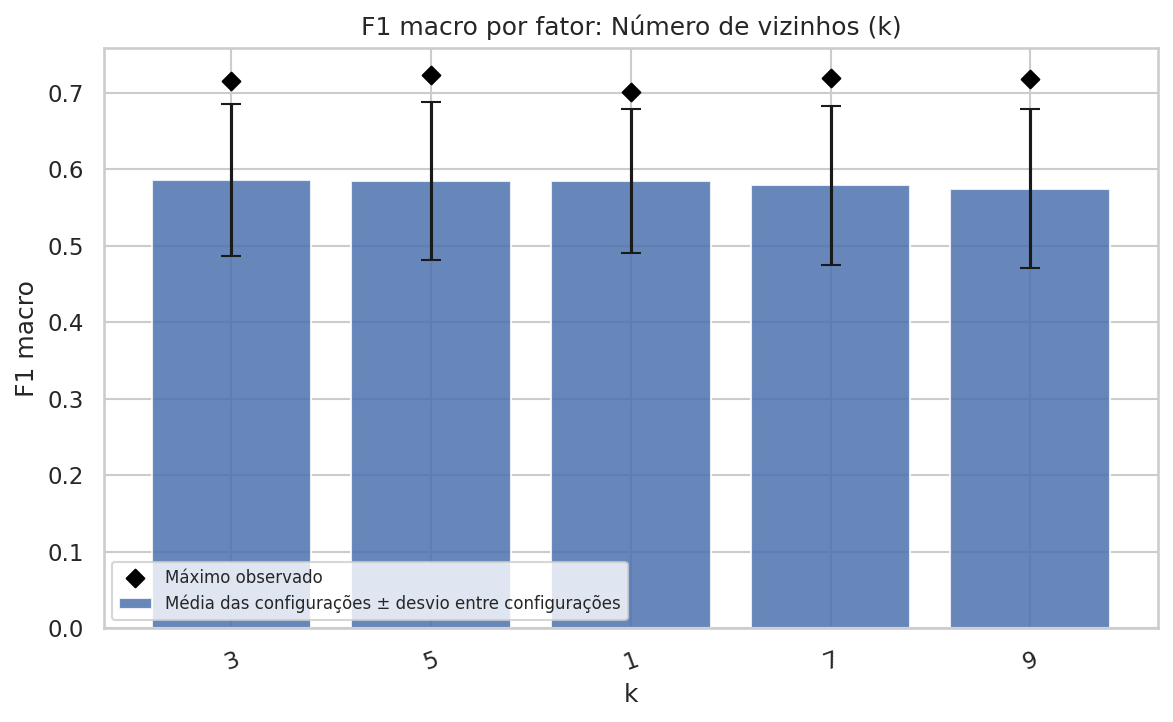

Leitura: Vizinhos k — o maior F1 observado é 0.7224 ; a média do nível líder é 0.5859 .


In [3]:
cont, longo, corr = graficos(df,exp)
fatores = [('max_ausentes','Limite de ausentes'),('imputador','Imputação'),('scaler','Scaler'),('metrica','Distância'),('pesos','Pesos'),('k','Vizinhos k')]
for coluna, nome in fatores:
    agg = exp.assign(**{coluna:exp[coluna].fillna('Sem limite').astype(str)}).groupby(coluna)['f1_macro'].agg(['mean','max','std','count']).sort_values('mean',ascending=False)
    display(Markdown(f'**{nome}: média, máximo, desvio entre configurações e quantidade de experimentos**'))
    display(agg.round(4))
    display(Image(filename=str(FIG / f'experimentos_fator_{coluna}.png'),width=800))
    print('Leitura:', nome, '— o maior F1 observado é', round(agg['max'].max(),4), '; a média do nível líder é',round(agg.iloc[0]['mean'],4),'.')

## 3. Com limite de ausentes × sem limite
**Atenção:** são bases de tamanhos diferentes: 5.104 instâncias sem filtro e 3.337 com até seis meses ausentes. Comparações são descritivas; alteração na população avaliada confunde o efeito do pré-processamento.

In [4]:
tab_limite=(exp.assign(cenario=exp['max_ausentes'].apply(lambda x:'Sem limite (5.104)' if pd.isna(x) else 'Até 6 ausentes (3.337)'))
 .groupby('cenario').agg(experimentos=('id','count'),n_instancias=('n_instancias','first'),f1_macro_medio=('f1_macro','mean'),f1_macro_maximo=('f1_macro','max'),f1_std_medio=('f1_std','mean')))
display(tab_limite.round(4))
print('Diferença entre os máximos:',round(tab_limite.f1_macro_maximo.max()-tab_limite.f1_macro_maximo.min(),4))

,experimentos,n_instancias,f1_macro_medio,f1_macro_maximo,f1_std_medio
cenario,,,,,
Até 6 ausentes (3.337),180,3337,0.6657,0.7224,0.0455
Sem limite (5.104),180,5104,0.4972,0.5811,0.0370


Diferença entre os máximos: 0.1412


## 4. Os cinco melhores são realmente diferentes?
Comparar amplitude entre o primeiro e o quinto com `f1_std` das próprias cinco configurações. Este critério é apenas **descritivo**, não é teste formal de significância, especialmente porque os modelos compartilham dados/folds.

In [5]:
top5=exp.nlargest(5,'f1_macro')
amplitude=top5.f1_macro.max()-top5.f1_macro.min()
print('Amplitude top 5:',round(amplitude,6))
print('Desvios entre folds (top 5):', [round(z,6) for z in top5.f1_std])
print('Menor desvio entre folds:',round(top5.f1_std.min(),6))
print('Amplitude < menor desvio?',amplitude < top5.f1_std.min())
assert amplitude < top5.f1_std.min()

Amplitude top 5: 0.003741
Desvios entre folds (top 5): [0.043573, 0.040105, 0.042837, 0.056918, 0.048987]
Menor desvio entre folds: 0.040105
Amplitude < menor desvio? True


## 5. EDA: distribuição das classes
**Decisão:** a desigualdade de frequências favorece reportar F1 macro em vez de depender somente da acurácia.

,registros,percentual
Mesorregiao,,
Agreste Pernambucano,1568,30.72
Sertão Pernambucano,1520,29.78
Mata Pernambucana,1024,20.06
Metropolitana do Recife,496,9.72
São Francisco Pernambucano,496,9.72


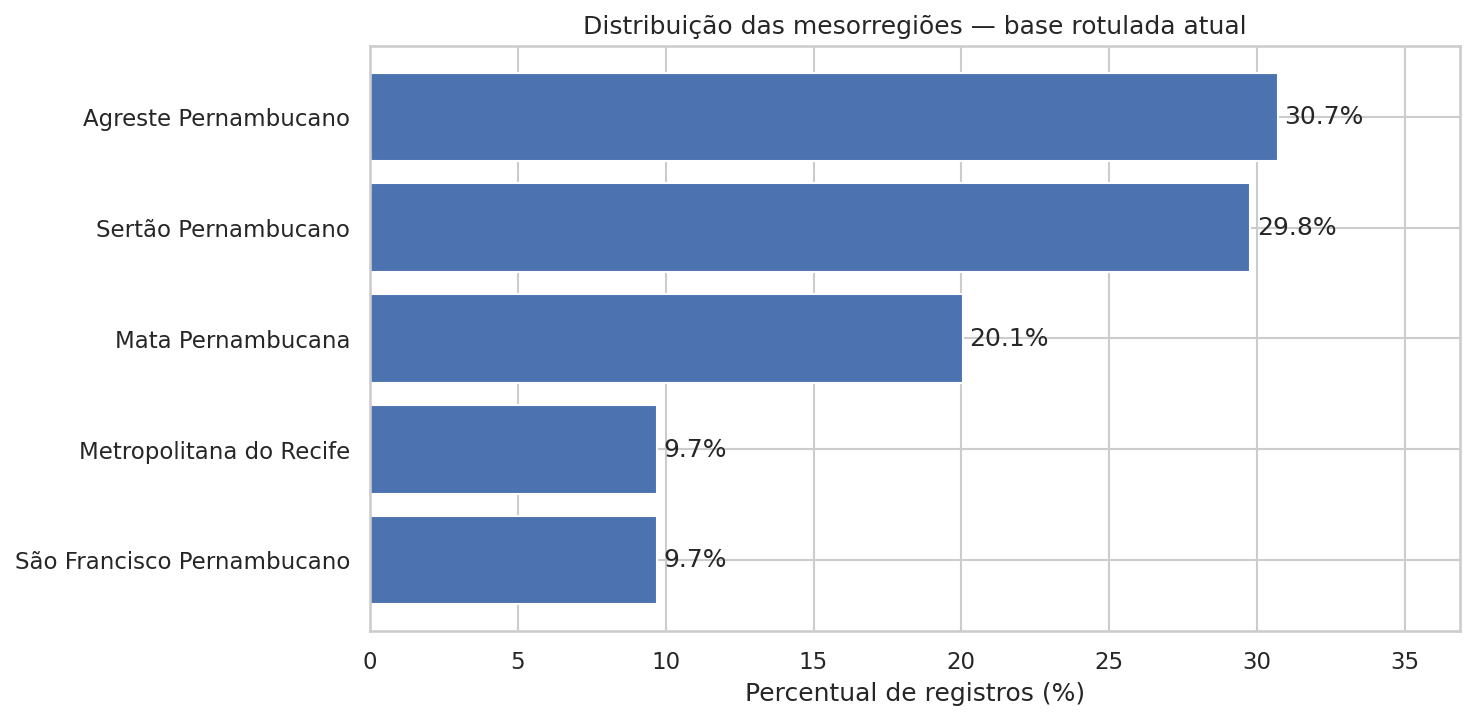

In [6]:
display(pd.DataFrame({'registros':cont,'percentual':(100*cont/len(df)).round(2)}))
display(Image(filename=str(FIG/'eda_distribuicao_classes.png'),width=850))

## 6. EDA: precipitação por mês e mesorregião
**Decisão:** os diferentes perfis de chuva reforçam o uso dos 12 meses como atributos; os boxplots omitem visualmente pontos extremos, **sem remover valores dos cálculos/modelos**.

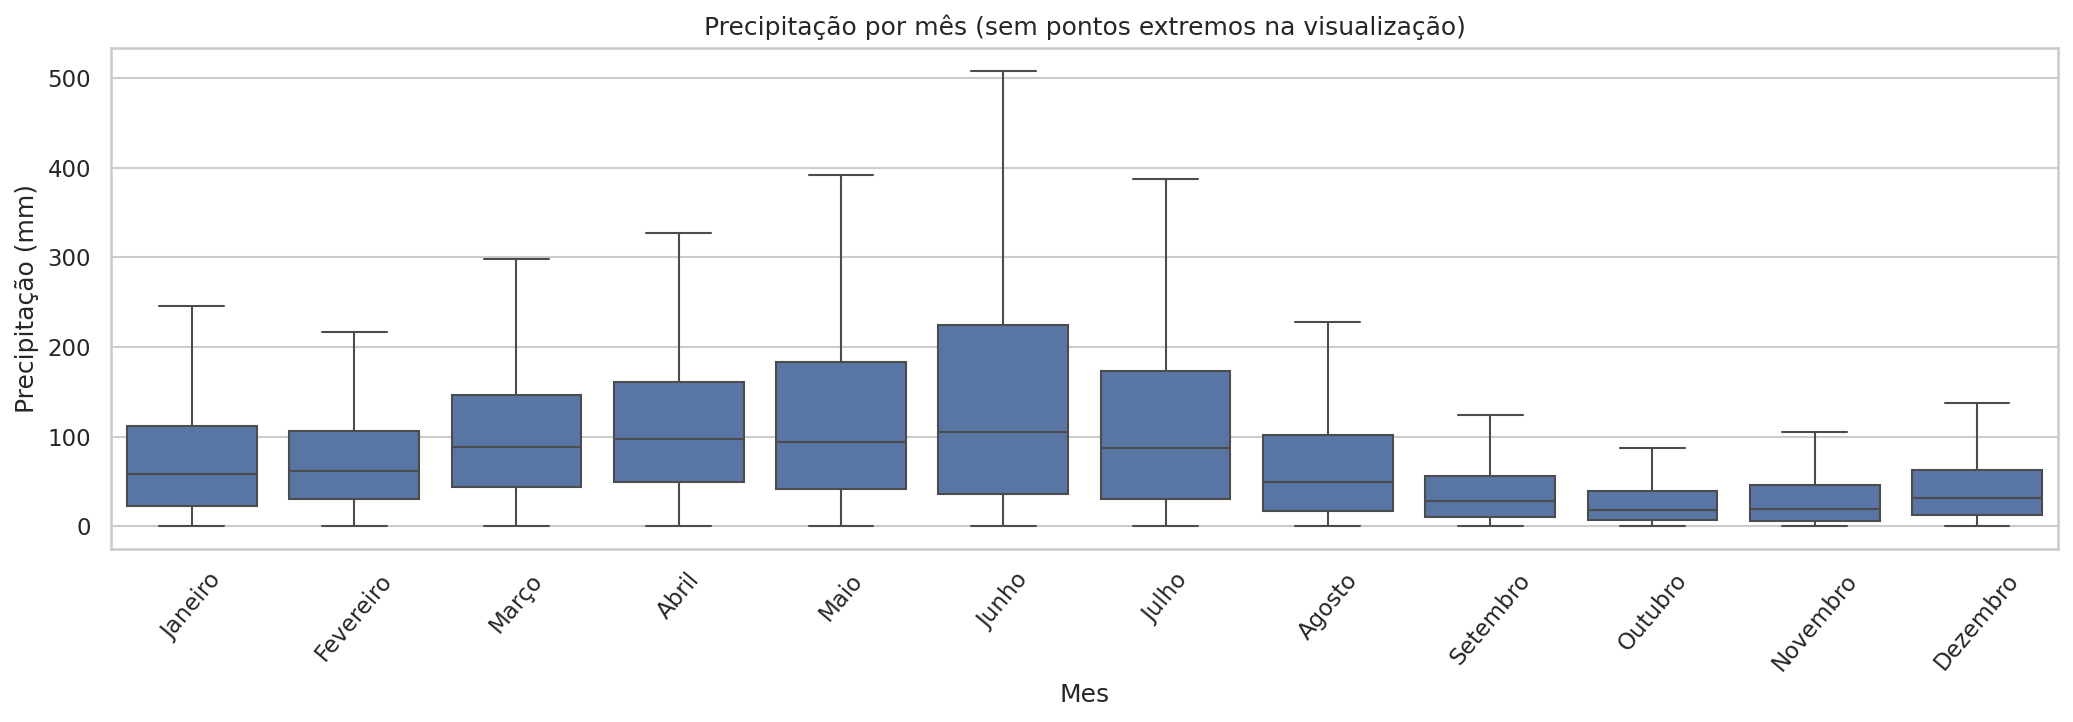

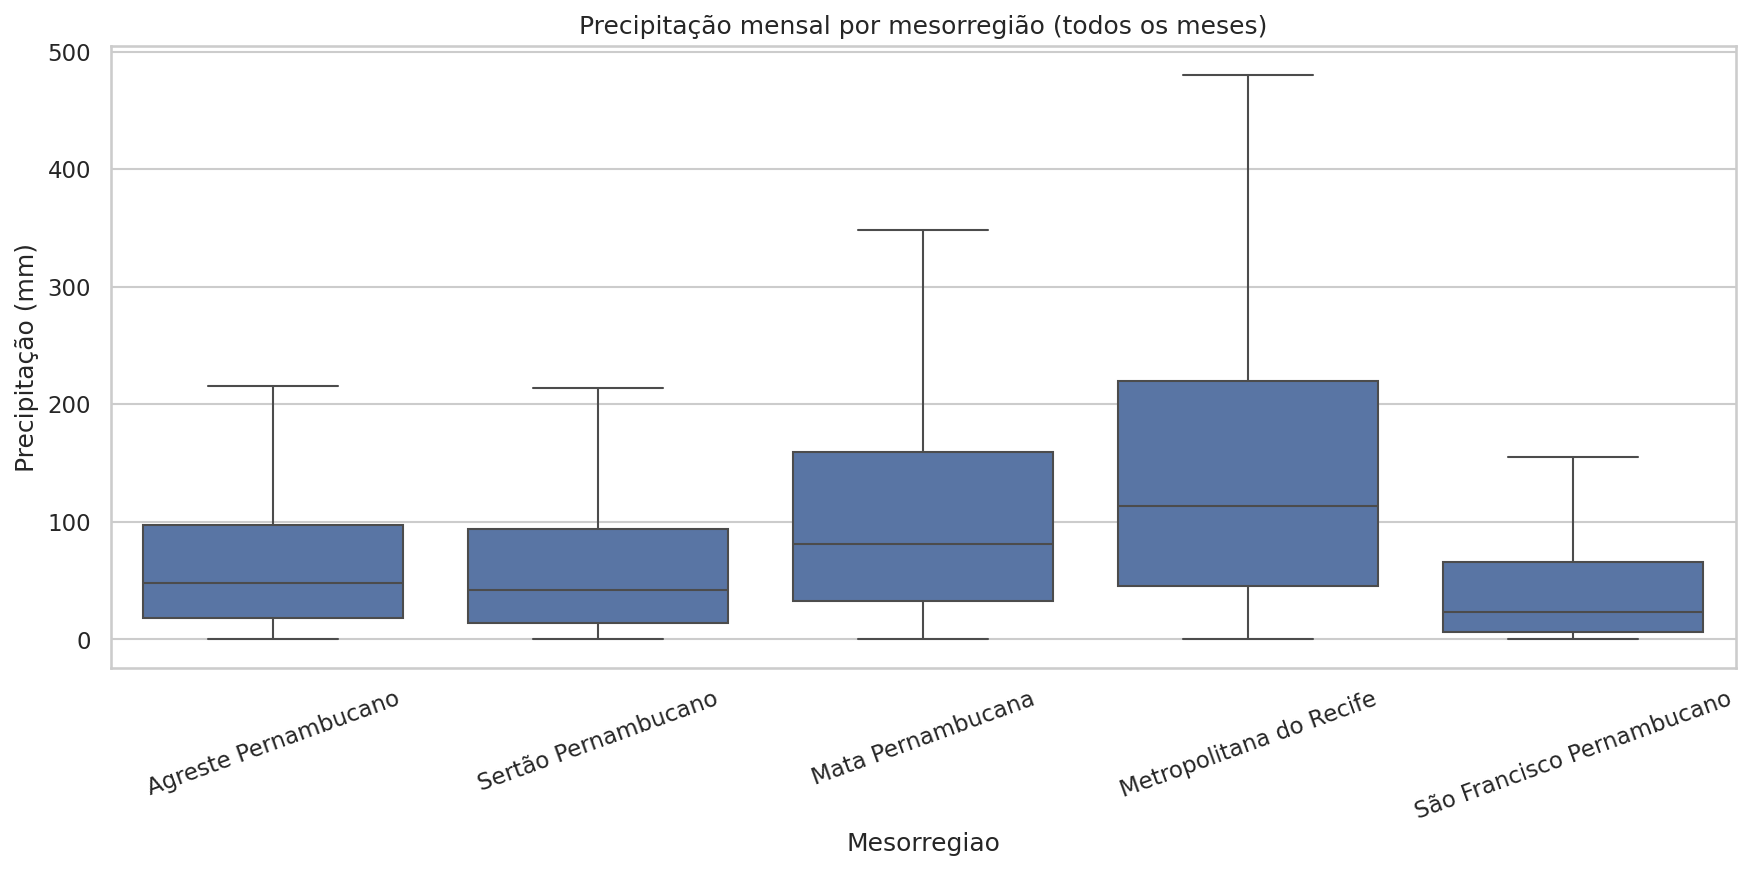

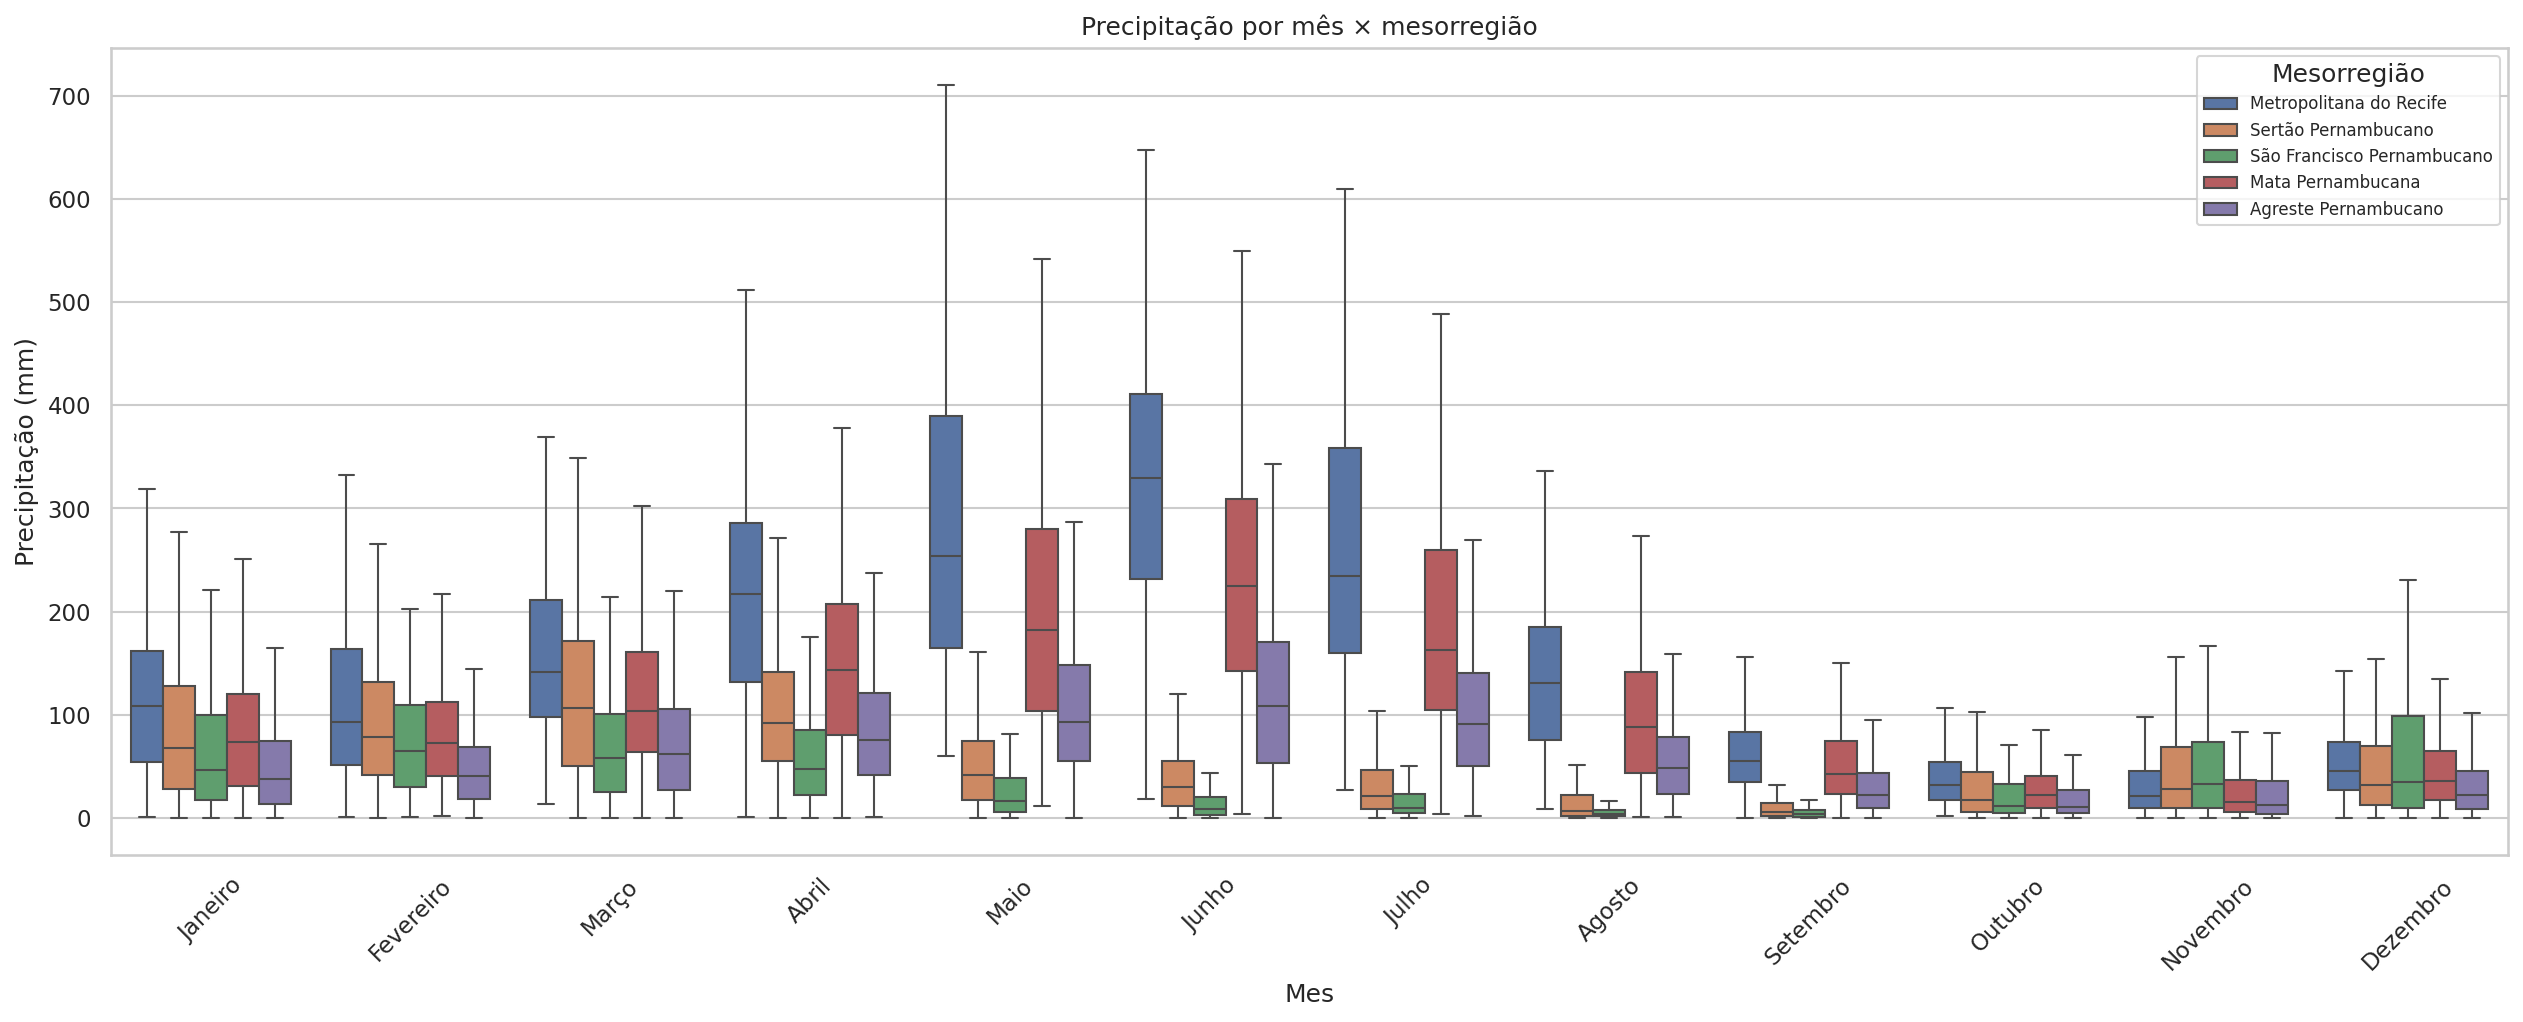

Medianas mensais (mm) por mesorregião:


Mes,Janeiro,Fevereiro,Março,Abril,Maio,Junho,Julho,Agosto,Setembro,Outubro,Novembro,Dezembro
Mesorregiao,,,,,,,,,,,,
Agreste Pernambucano,37.5,40.7,62.3,75.7,93.4,108.3,91.1,48.6,22.3,11.0,12.6,22.1
Mata Pernambucana,73.9,72.7,103.6,143.5,182.6,225.0,163.2,88.4,43.0,22.0,15.5,36.0
Metropolitana do Recife,108.6,92.6,141.6,217.0,254.2,329.2,234.1,131.2,54.8,32.3,21.0,45.2
Sertão Pernambucano,68.0,78.5,106.5,91.6,41.7,29.6,21.0,7.0,5.5,17.5,28.0,32.2
São Francisco Pernambucano,46.2,64.7,57.8,47.3,16.0,8.7,10.0,4.0,3.6,12.0,33.3,35.1


In [7]:
display(Image(filename=str(FIG/'eda_boxplot_meses.png'),width=1000))
display(Image(filename=str(FIG/'eda_boxplot_mesorregioes.png'),width=950))
display(Image(filename=str(FIG/'eda_boxplot_mes_regiao.png'),width=1100))
print('Medianas mensais (mm) por mesorregião:')
display(longo.pivot_table(index='Mesorregiao',columns='Mes',values='Chuva_mm',aggfunc='median').reindex(columns=MESES).round(1))

## 7. EDA: correlação entre os 12 meses
**Decisão:** correlações informam redundância potencial entre atributos; não justificam descartar meses sem uma avaliação dentro da validação cruzada. Correlação calculada com pares de observações disponíveis (`NaN` ignorado por par).

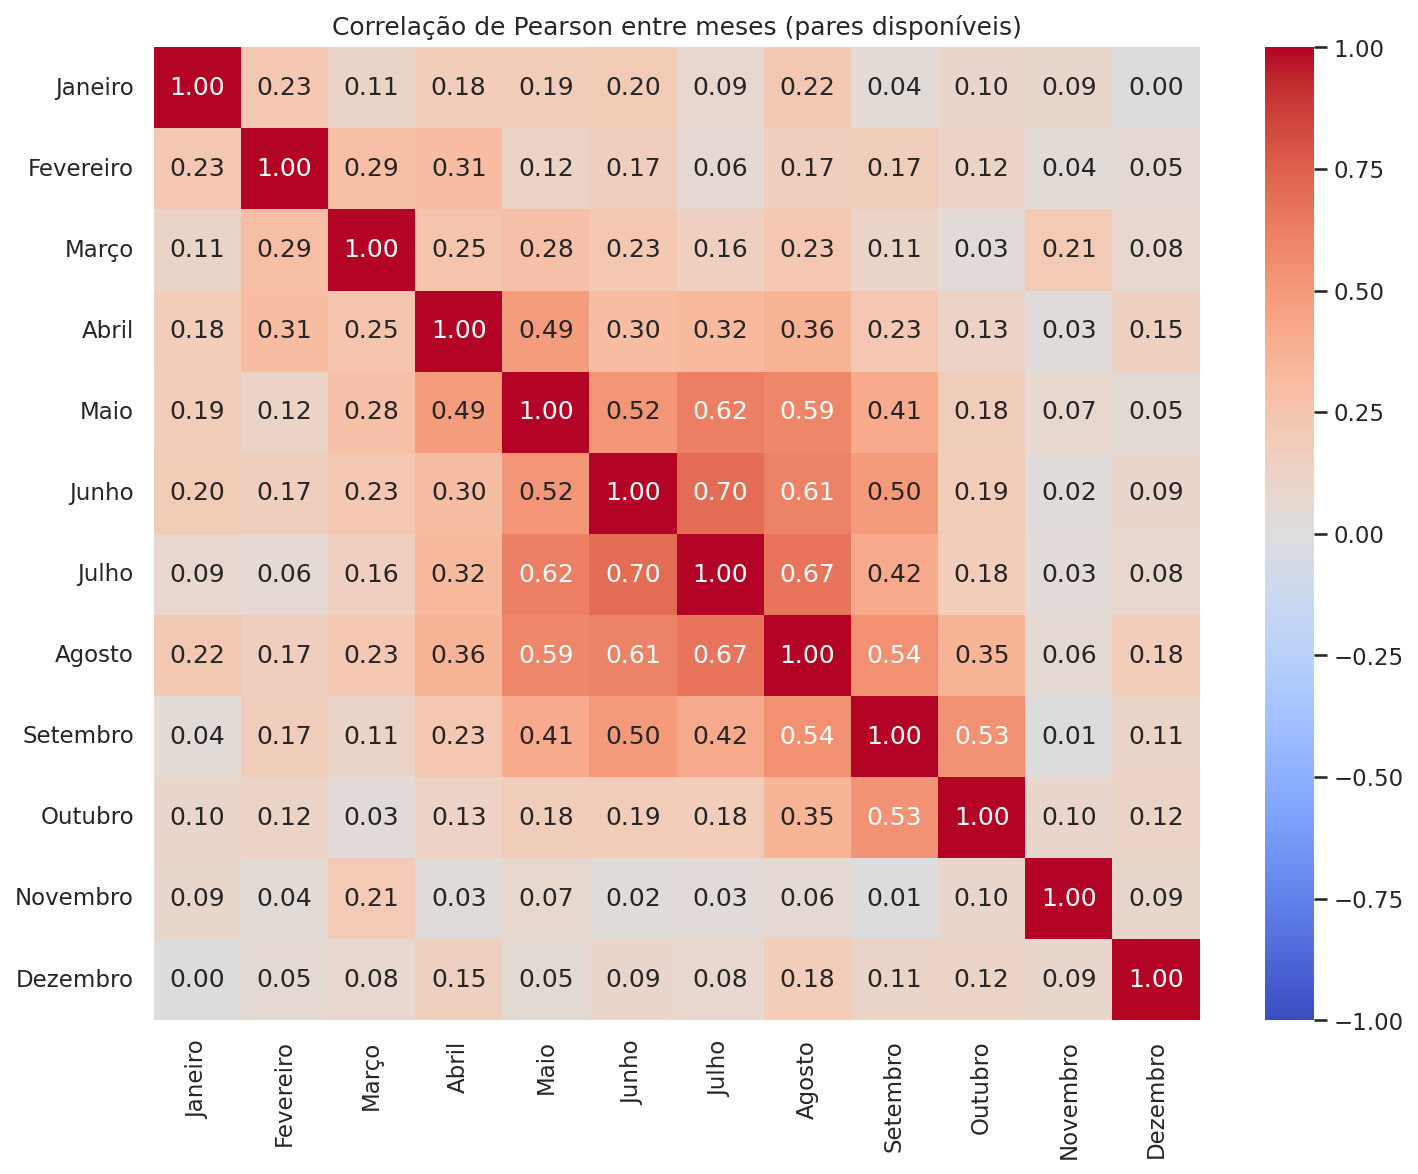

Maior correlação positiva: ('Junho', 'Julho') 0.696
Menor correlação: ('Janeiro', 'Dezembro') 0.005


In [8]:
display(Image(filename=str(FIG/'eda_correlacao_meses.png'),width=900))
pares=corr.where(~pd.np.eye(len(corr),dtype=bool)).stack() if False else None
import numpy as np
mat=corr.where(np.triu(np.ones(corr.shape,dtype=bool),k=1)).stack().sort_values(ascending=False)
print('Maior correlação positiva:',mat.index[0],round(mat.iloc[0],3))
print('Menor correlação:',mat.index[-1],round(mat.iloc[-1],3))

## 8. Síntese pronta para relatório e pitch
**Cuidado interpretativo:** as métricas do CSV antecedem as correções do alvo na Issue #4. Não apresentá-las como avaliação da versão corrigida do projeto.

In [9]:
melhor=exp.nlargest(1,'f1_macro').iloc[0]
texto=(f'Na análise histórica de {len(exp)} configurações do KNN sobre precipitação mensal da APAC, '
       f'o maior F1 macro observado foi {melhor.f1_macro:.3f} (desvio entre folds {melhor.f1_std:.3f}), '
       f'com {int(melhor.n_instancias):,} instâncias, imputação {melhor.imputador}, scaler {melhor.scaler}, '
       f'k={int(melhor.k)}, peso {melhor.pesos} e distância {melhor.metrica}. '
       f'Os cinco melhores variaram apenas {amplitude:.4f} em F1 macro, valor inferior ao menor desvio entre folds '
       f'({top5.f1_std.min():.4f}), não permitindo sustentar superioridade robusta de uma única configuração. '
       f'Na EDA, a distribuição regional é desbalanceada e os perfis mensais de precipitação diferem entre regiões, '
       f'justificando o F1 macro e a análise sazonal. '
       f'Os resultados dos experimentos antecedem as correções de rótulos da Issue #4 e devem ser recalculados para a entrega final.')
print('PARÁGRAFO PARA RELATÓRIO:\n'+texto)
print('\nPITCH (4 tópicos):')
for t in ['Base APAC: 5.104 observações, 12 meses e 5 mesorregiões (distribuição desigual).',
          'EDA: comparar precipitação mensal e diferenças regionais, sem descartar extremos apenas por boxplot.',
          f'Grade histórica de 360 configurações: melhor F1 macro {melhor.f1_macro:.3f} ± {melhor.f1_std:.3f}.',
          f'Top 5 diferem {amplitude:.4f}: diferença menor que a variação observada entre folds; reexecutar após Issue #4.']:
    print('•',t)
print('\nFiguras geradas:',len(list(FIG.glob('*.png'))))

PARÁGRAFO PARA RELATÓRIO:
Na análise histórica de 360 configurações do KNN sobre precipitação mensal da APAC, o maior F1 macro observado foi 0.722 (desvio entre folds 0.044), com 3,337 instâncias, imputação mediana, scaler standard, k=5, peso distance e distância manhattan. Os cinco melhores variaram apenas 0.0037 em F1 macro, valor inferior ao menor desvio entre folds (0.0401), não permitindo sustentar superioridade robusta de uma única configuração. Na EDA, a distribuição regional é desbalanceada e os perfis mensais de precipitação diferem entre regiões, justificando o F1 macro e a análise sazonal. Os resultados dos experimentos antecedem as correções de rótulos da Issue #4 e devem ser recalculados para a entrega final.

PITCH (4 tópicos):
• Base APAC: 5.104 observações, 12 meses e 5 mesorregiões (distribuição desigual).
• EDA: comparar precipitação mensal e diferenças regionais, sem descartar extremos apenas por boxplot.
• Grade histórica de 360 configurações: melhor F1 macro 0.722 